# Adding ventricles and CSF to nxbsimplified labels

This notebook shows the process and results of `add_csf_to_labels.py` (see `TODO.txt`) for each case.

**Ventricles** (label 50, NextBrain `anterior_horn_of_lateral_ventricle`): background enclosed by the
*non-cortical* brain (WM + deep GM; cortex 3 and cerebellar cortex 595/597 are excluded, so sulci are never
enclosed). Hole filling is done in 3D **and** slice by slice in sagittal slices, because the hemispheres are cut and the
ventricles are open on the medial face. Pockets smaller than 1 mm³ are filled with the nearest tissue label, and the
ventricle mask is closed (2 mm, background voxels only) to bridge slices where it is open even in 2D.

**CSF** (label 24, FreeSurfer CSF): brain mask (tissue + ventricles) → close the cortex (2 mm closing + 3D hole
filling) → dilate 1 mm → CSF = dilated − brain mask.

The outputs come from running the script with `--save-intermediates`:
```
cd morphological_approach
python add_csf_to_labels.py --save-intermediates
```

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

ROOT = Path.cwd().parent  # add_csf_to_labels/ (shared data/)
IN_DIR = ROOT / "data" / "inputs" / "nxbsimplified" / "labels"
OUT_DIR = ROOT / "data" / "outputs" / "morphological_approach"
summary = json.load(open(OUT_DIR / "summary.json"))
P = summary["params"]
VENT, CSF = P["ventricle_label"], P["csf_label"]
CASES = [c["case"] for c in summary["cases"]]
print(json.dumps(P, indent=1))
print(CASES)

{
 "cortex_labels": [
  3,
  595,
  597
 ],
 "bridge_mm": 0.4,
 "vent_close_mm": 2.0,
 "min_ventricle_mm3": 1.0,
 "close_mm_r": 2.0,
 "dilate_mm_r": 1.0,
 "ventricle_label": 50,
 "csf_label": 24
}
['case-1', 'case-2', 'case-3', 'case-4', 'case-5']


In [2]:
# label colour scheme (RAS volumes: axis 0 = L-R, 1 = P-A, 2 = I-S)
COLORS = {
    "background": (0, 0, 0),
    "cortex (3, 595, 597)": (0.88, 0.40, 0.40),
    "forebrain WM (7)": (0.93, 0.93, 0.93),
    "other tissue": (0.35, 0.58, 0.85),
    f"ventricle ({VENT})": (1.00, 0.82, 0.00),
    f"CSF ({CSF})": (0.20, 0.75, 0.35),
}

def colorize(s):
    rgb = np.zeros(s.shape + (3,))
    rgb[s > 0] = COLORS["other tissue"]
    rgb[np.isin(s, P["cortex_labels"])] = COLORS["cortex (3, 595, 597)"]
    rgb[s == 7] = COLORS["forebrain WM (7)"]
    rgb[s == VENT] = COLORS[f"ventricle ({VENT})"]
    rgb[s == CSF] = COLORS[f"CSF ({CSF})"]
    return rgb

def overlay(s, mask, color, alpha=0.75):
    """labels in grey + a binary mask on top"""
    rgb = np.repeat((0.25 + 0.35 * (s > 0))[..., None], 3, -1)
    rgb[np.isin(s, P["cortex_labels"])] *= 0.75
    rgb[mask] = (1 - alpha) * rgb[mask] + alpha * np.array(color)
    return rgb

def take(vol, axis, idx):
    """2D slice displayed with the superior / anterior direction up"""
    return np.take(vol, idx, axis=axis).T

VIEW = {0: "sagittal", 1: "coronal", 2: "axial"}

def show(ax, img, title):
    ax.imshow(img, origin="lower", interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.axis("off")

def legend(fig, items):
    fig.legend(handles=[Patch(color=COLORS[k] if k in COLORS else c, label=k) for k, c in items],
               loc="lower center", ncol=len(items), frameon=False, fontsize=10)

def load_case(case):
    d = {"input": np.asarray(nib.load(IN_DIR / f"{case}.nii.gz").dataobj),
         "output": np.asarray(nib.load(OUT_DIR / "labels" / f"{case}.nii.gz").dataobj)}
    idir = OUT_DIR / "intermediates" / case
    for f in sorted(idir.glob("*.nii.gz")):
        d[f.name.replace(".nii.gz", "")] = np.asarray(nib.load(f).dataobj).astype(bool)
    return d

def ventricle_slices(vent):
    """slices through the ventricle: centre of mass along each axis"""
    idx = np.nonzero(vent)
    return [int(np.median(i)) for i in idx]

In [3]:
STEPS = [
    ("1. input labels", None, None),
    ("2. non-cortex mask (closed)", "inner_mask", (0.35, 0.58, 0.85)),
    ("3. holes filled (3D + sagittal 2D)", "inner_filled", (0.6, 0.3, 0.9)),
    ("4. ventricles", "ventricles", COLORS[f"ventricle ({VENT})"]),
    ("5. brain mask closed (sulci)", "closed_mask", (0.9, 0.55, 0.1)),
    ("6. closed mask dilated", "dilated_mask", (0.1, 0.7, 0.8)),
    ("7. CSF = dilated − brain", "csf", COLORS[f"CSF ({CSF})"]),
    ("8. output labels", None, None),
]

def plot_process(case, d):
    sl = ventricle_slices(d["ventricles"])
    fig, axes = plt.subplots(3, len(STEPS), figsize=(3.2 * len(STEPS), 3 * 3.4))
    for r, axis in enumerate([0, 1, 2]):
        s_in = take(d["input"], axis, sl[axis])
        for c, (title, key, color) in enumerate(STEPS):
            if key is None:
                img = colorize(s_in if c == 0 else take(d["output"], axis, sl[axis]))
            else:
                img = overlay(s_in, take(d[key], axis, sl[axis]), color)
            show(axes[r, c], img, title if r == 0 else "")
        axes[r, 0].text(-0.05, 0.5, f"{VIEW[axis]} {sl[axis]}", transform=axes[r, 0].transAxes,
                        rotation=90, va="center", ha="right", fontsize=11)
    fig.suptitle(f"{case}: process (slices through the ventricle centre)", fontsize=14)
    plt.tight_layout()
    plt.show()

def plot_result(case, d, fracs=(0.35, 0.5, 0.65)):
    """input vs output, 3 slices per view spread over the brain extent"""
    idx = np.nonzero(d["output"] > 0)
    lo = [i.min() for i in idx]; hi = [i.max() for i in idx]
    fig, axes = plt.subplots(3, 2 * len(fracs), figsize=(3.6 * 2 * len(fracs), 3 * 3.6))
    for r, axis in enumerate([0, 1, 2]):
        for j, f in enumerate(fracs):
            k = int(lo[axis] + f * (hi[axis] - lo[axis]))
            show(axes[r, 2 * j], colorize(take(d["input"], axis, k)), f"{VIEW[axis]} {k}: input")
            show(axes[r, 2 * j + 1], colorize(take(d["output"], axis, k)), f"{VIEW[axis]} {k}: output")
    legend(fig, [(k, None) for k in COLORS if k != "background"])
    fig.suptitle(f"{case}: input vs output", fontsize=14)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()

def plot_zoom(case, d, half=60):
    """zoom (±half voxels = ±12 mm) around the ventricle centre"""
    sl = ventricle_slices(d["ventricles"])
    fig, axes = plt.subplots(1, 6, figsize=(24, 4.4))
    for j, axis in enumerate([0, 1, 2]):
        o = [a for a in range(3) if a != axis]
        win = [slice(max(sl[a] - 2 * half, 0), sl[a] + 2 * half) for a in o]
        def crop(v):
            return take(v, axis, sl[axis])[win[1], win[0]]
        show(axes[2 * j], colorize(crop(d["input"])), f"{VIEW[axis]} {sl[axis]}: input")
        show(axes[2 * j + 1], colorize(crop(d["output"])), f"{VIEW[axis]} {sl[axis]}: output")
    fig.suptitle(f"{case}: zoom around the ventricle (±24 mm)", fontsize=13)
    plt.tight_layout()
    plt.show()

def volumes(case, d, vox_mm3):
    u, c = np.unique(d["output"], return_counts=True)
    v = dict(zip(u.tolist(), (c * vox_mm3 / 1000).tolist()))
    return {"case": case,
            "tissue (cm3)": sum(x for k, x in v.items() if k not in (0, VENT, CSF)),
            "ventricle (cm3)": v.get(VENT, 0.0),
            "CSF (cm3)": v.get(CSF, 0.0),
            "small pockets filled (cm3)": d["small_pockets"].sum() * vox_mm3 / 1000}

## Per-case process and results

For each case: (a) every step, as an overlay on the input labels, on sagittal / coronal / axial slices through the ventricle centre; (b) a zoom around the ventricle; (c) input vs output at three positions per view.

### case-1

{'case': 'case-1', 'tissue (cm3)': 544.226529849372, 'ventricle (cm3)': 9.190080436505378, 'CSF (cm3)': 75.18881957127712, 'small pockets filled (cm3)': np.float64(0.1505840071523562)}


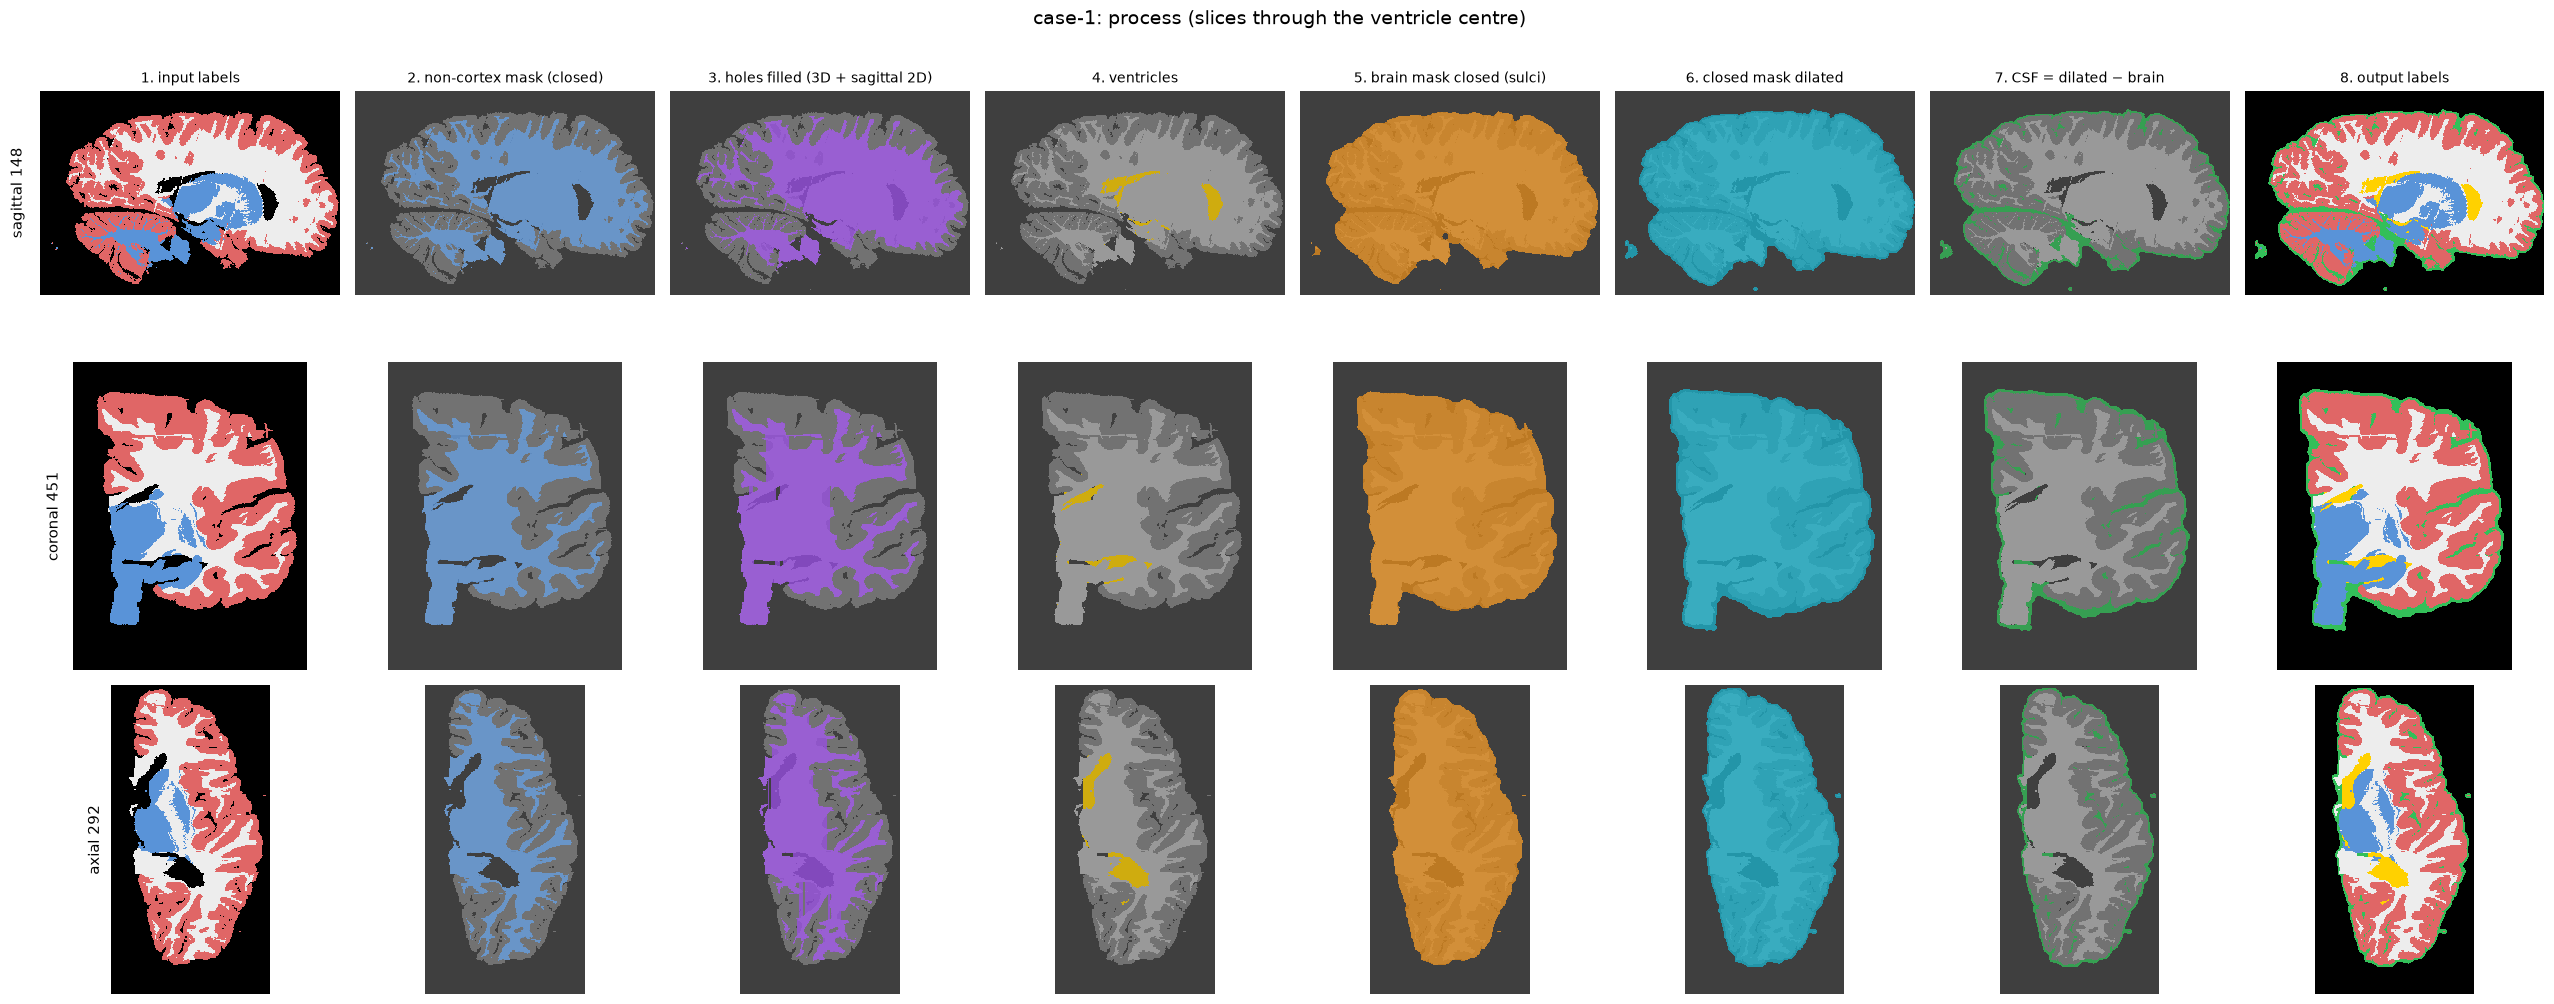

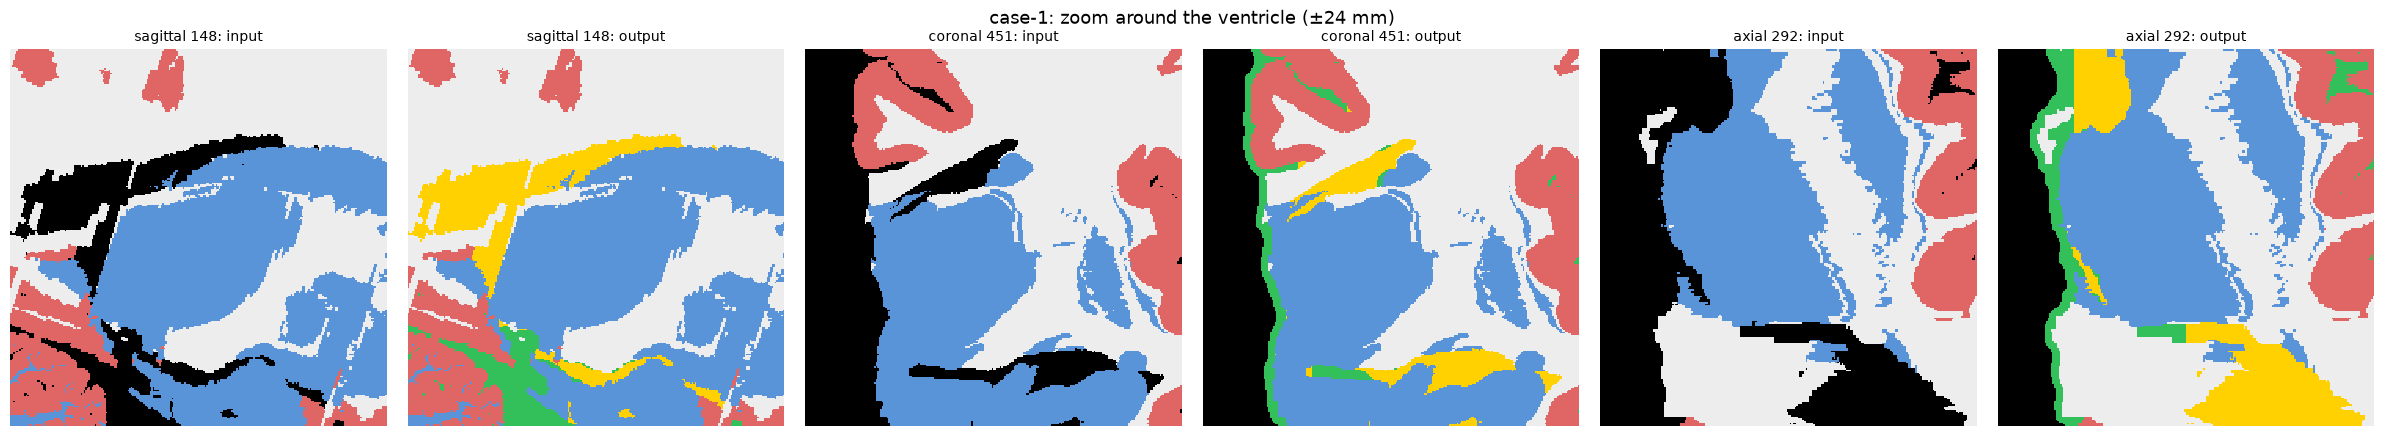

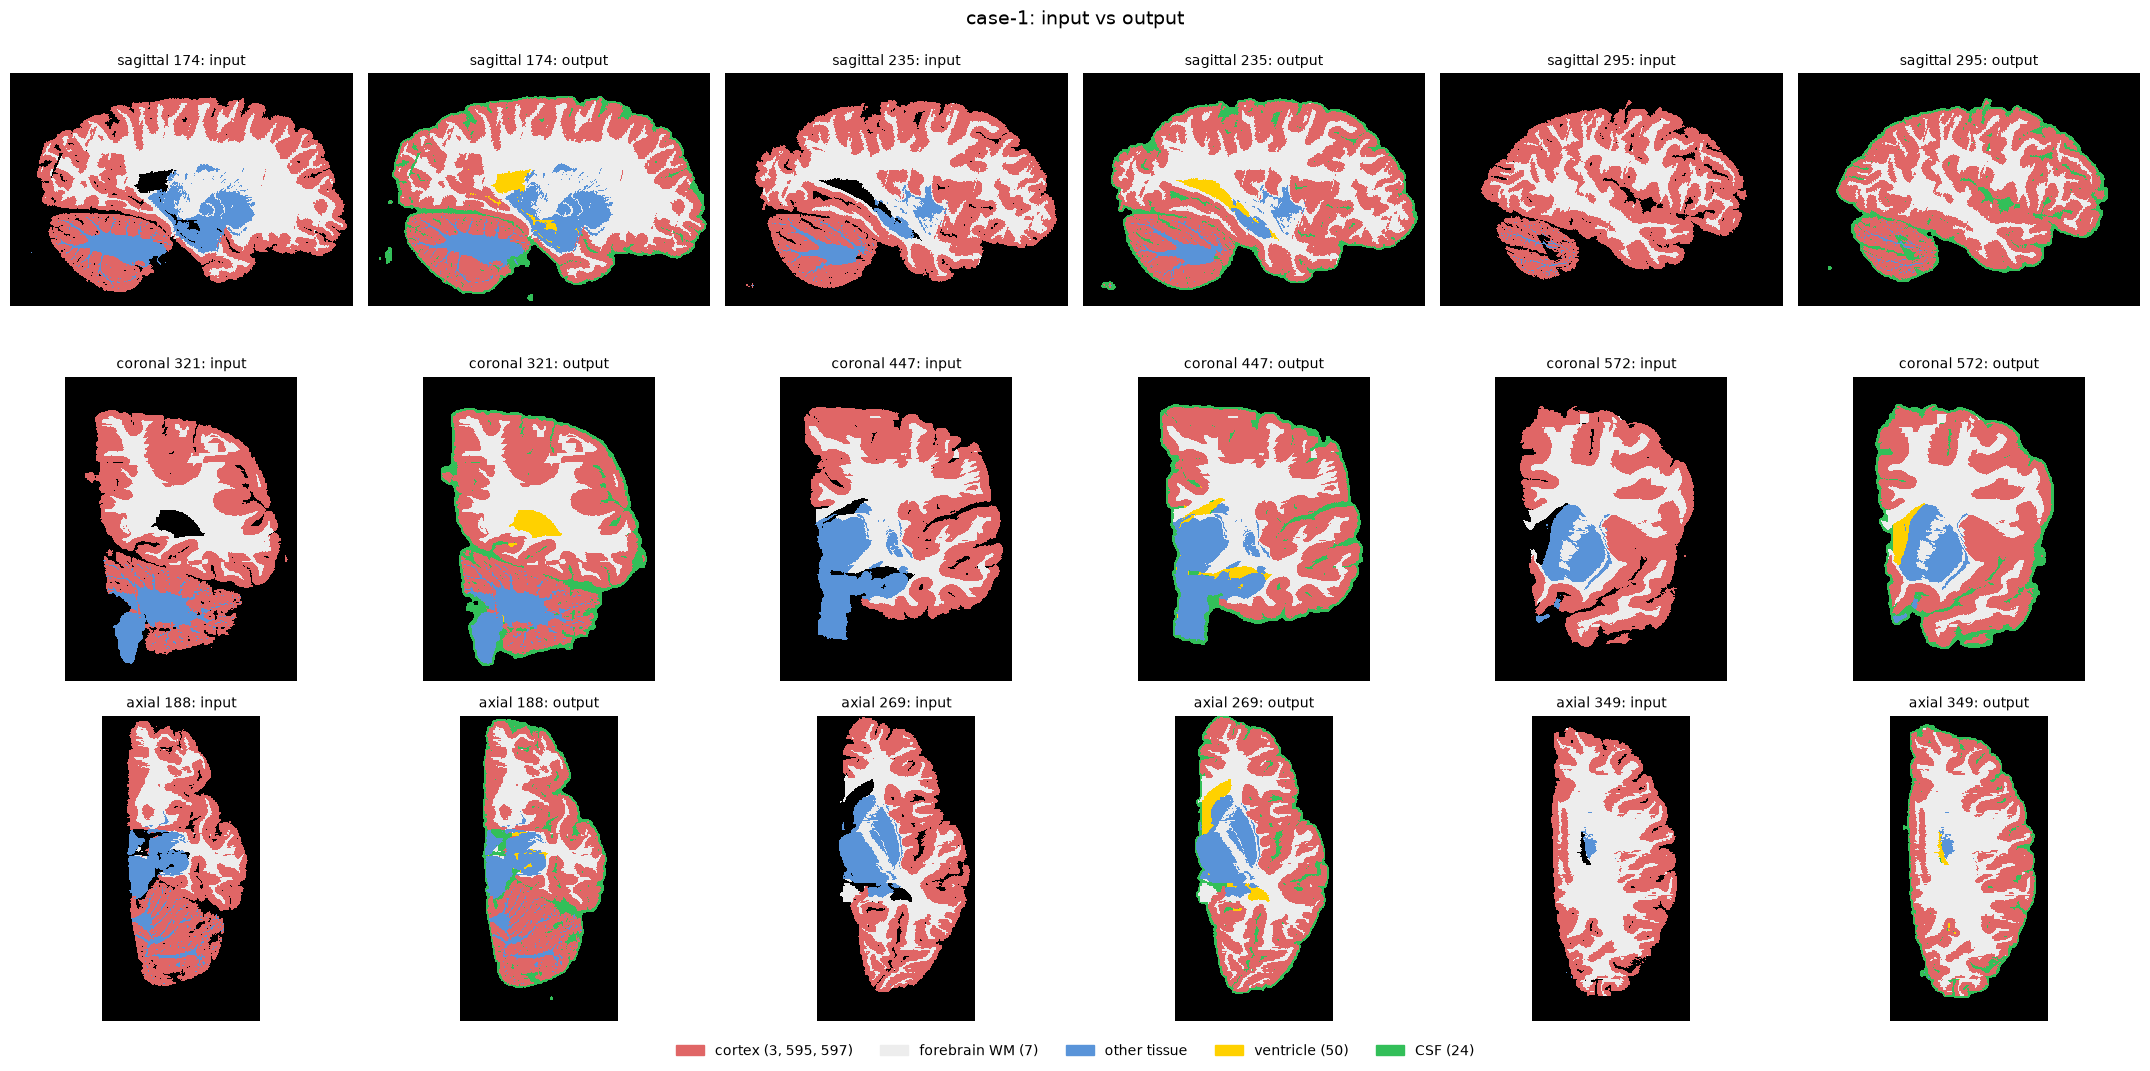

In [4]:
case = "case-1"
d = load_case(case)
vox = float(np.prod(nib.load(IN_DIR / f"{case}.nii.gz").header.get_zooms()[:3]))
rows = globals().setdefault("ROWS", {})
rows[case] = volumes(case, d, vox)
print(rows[case])
plot_process(case, d)
plot_zoom(case, d)
plot_result(case, d)
del d

### case-2

{'case': 'case-2', 'tissue (cm3)': 509.55379220250535, 'ventricle (cm3)': 14.535104690380395, 'CSF (cm3)': 64.0027950399695, 'small pockets filled (cm3)': np.float64(0.14559200691524893)}


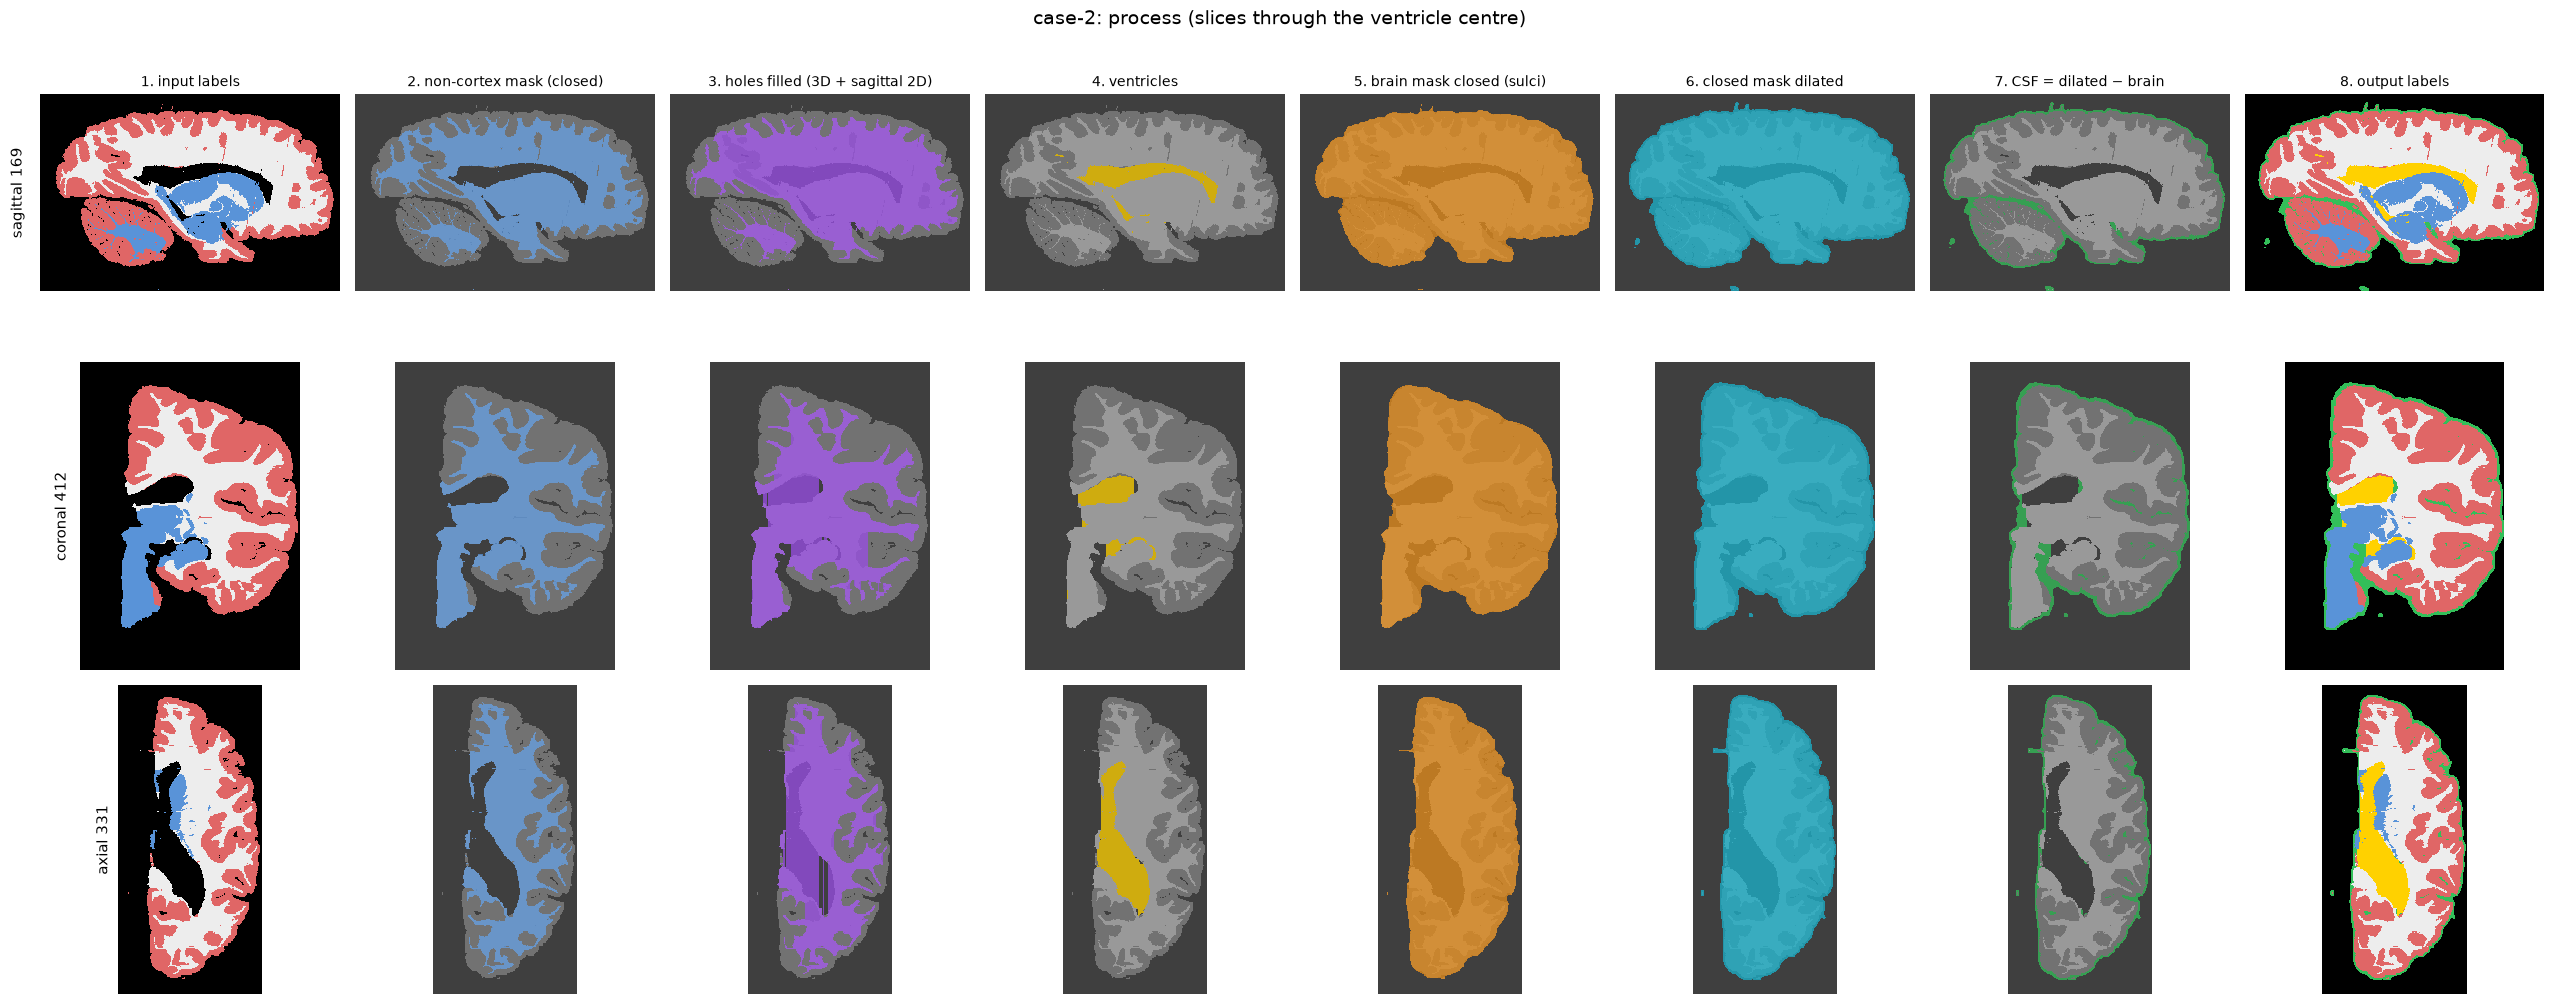

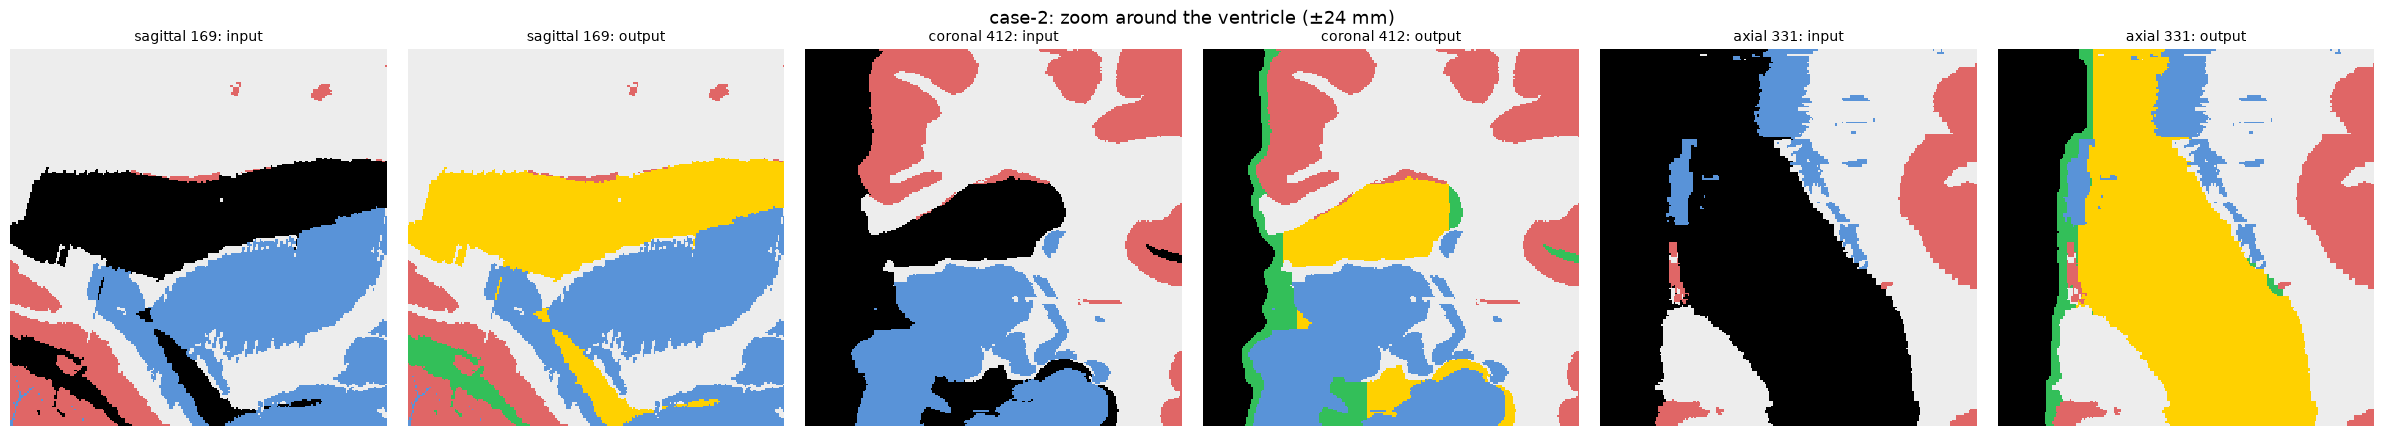

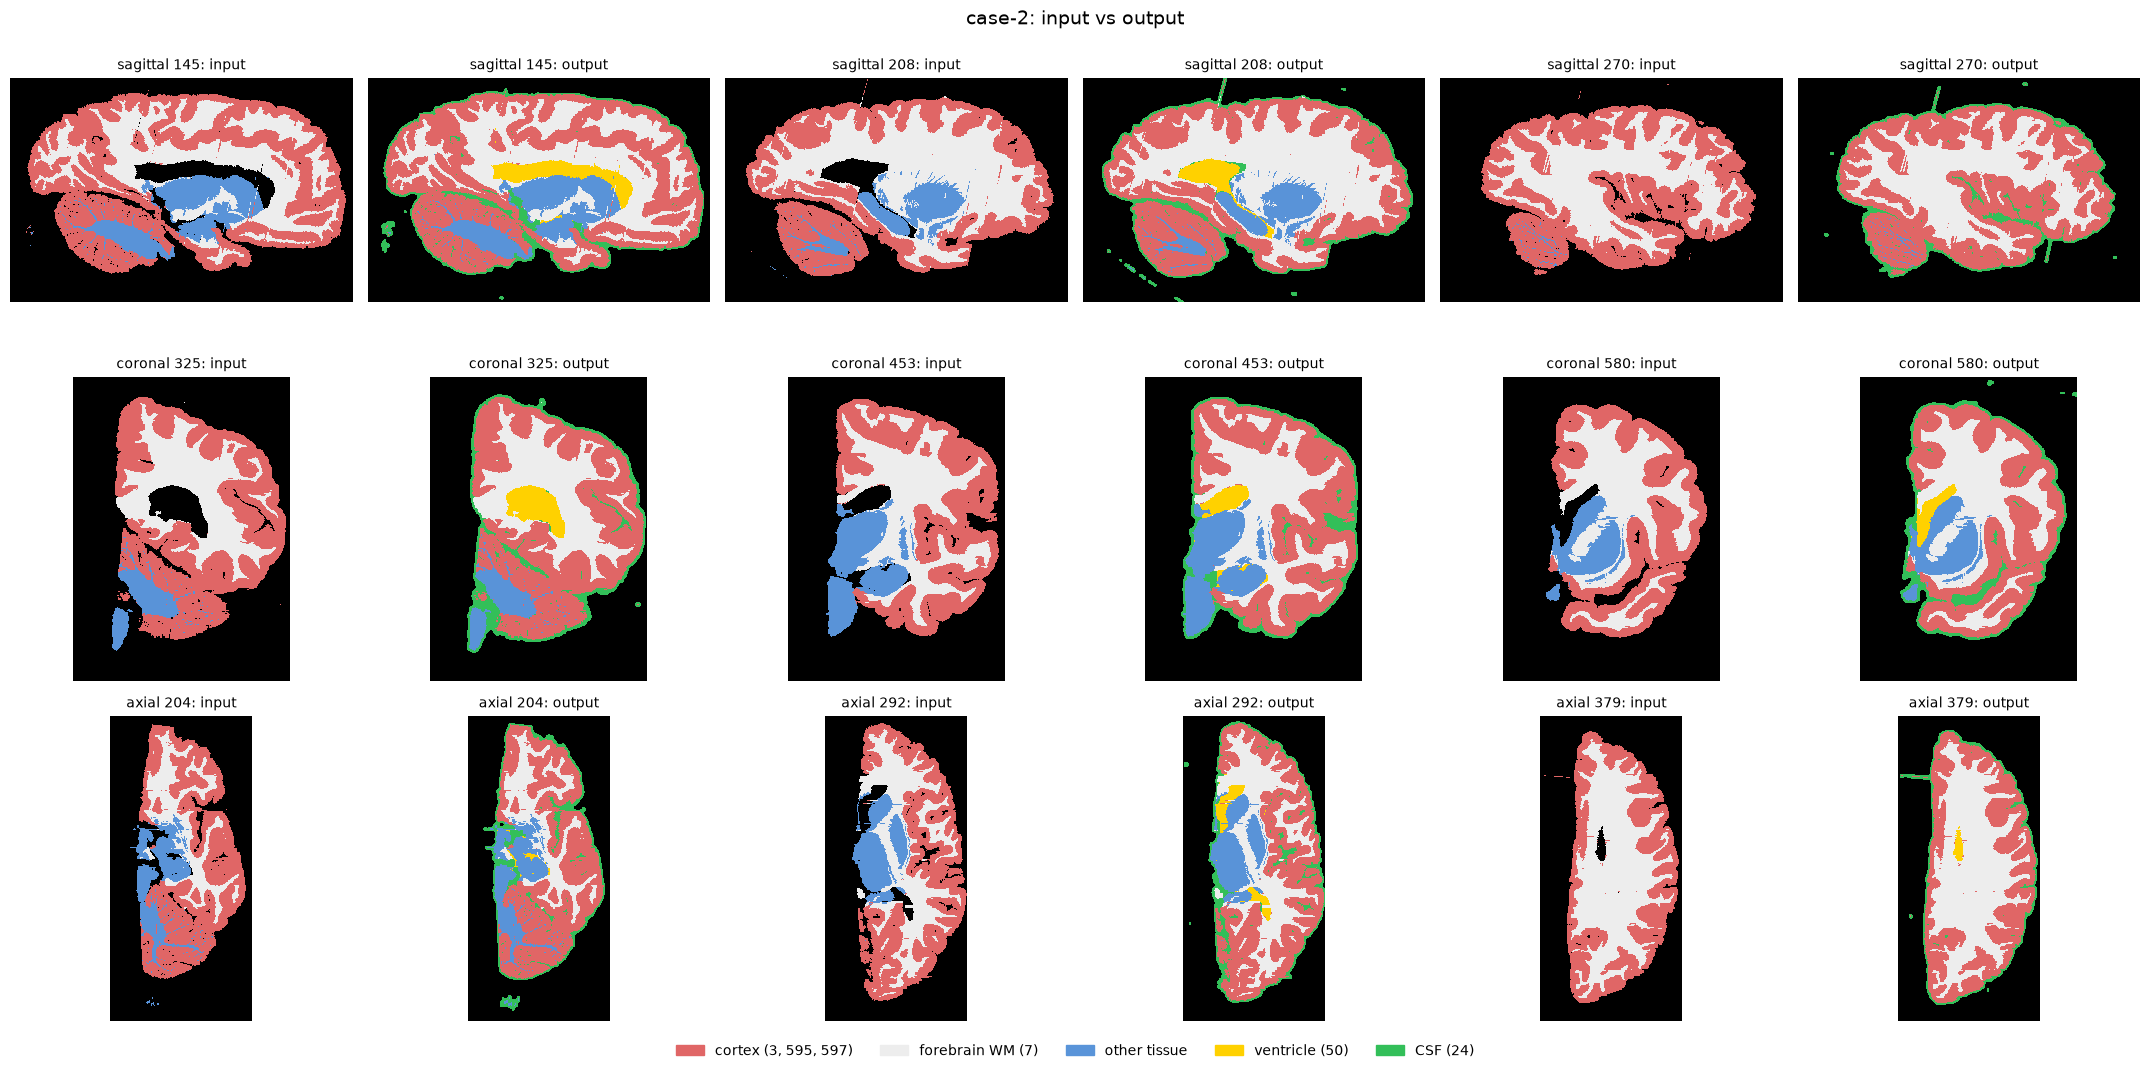

In [5]:
case = "case-2"
d = load_case(case)
vox = float(np.prod(nib.load(IN_DIR / f"{case}.nii.gz").header.get_zooms()[:3]))
rows = globals().setdefault("ROWS", {})
rows[case] = volumes(case, d, vox)
print(rows[case])
plot_process(case, d)
plot_zoom(case, d)
plot_result(case, d)
del d

### case-3

{'case': 'case-3', 'tissue (cm3)': 567.0259869322884, 'ventricle (cm3)': 14.671824696874246, 'CSF (cm3)': 80.03583580149804, 'small pockets filled (cm3)': np.float64(0.18283200868405403)}


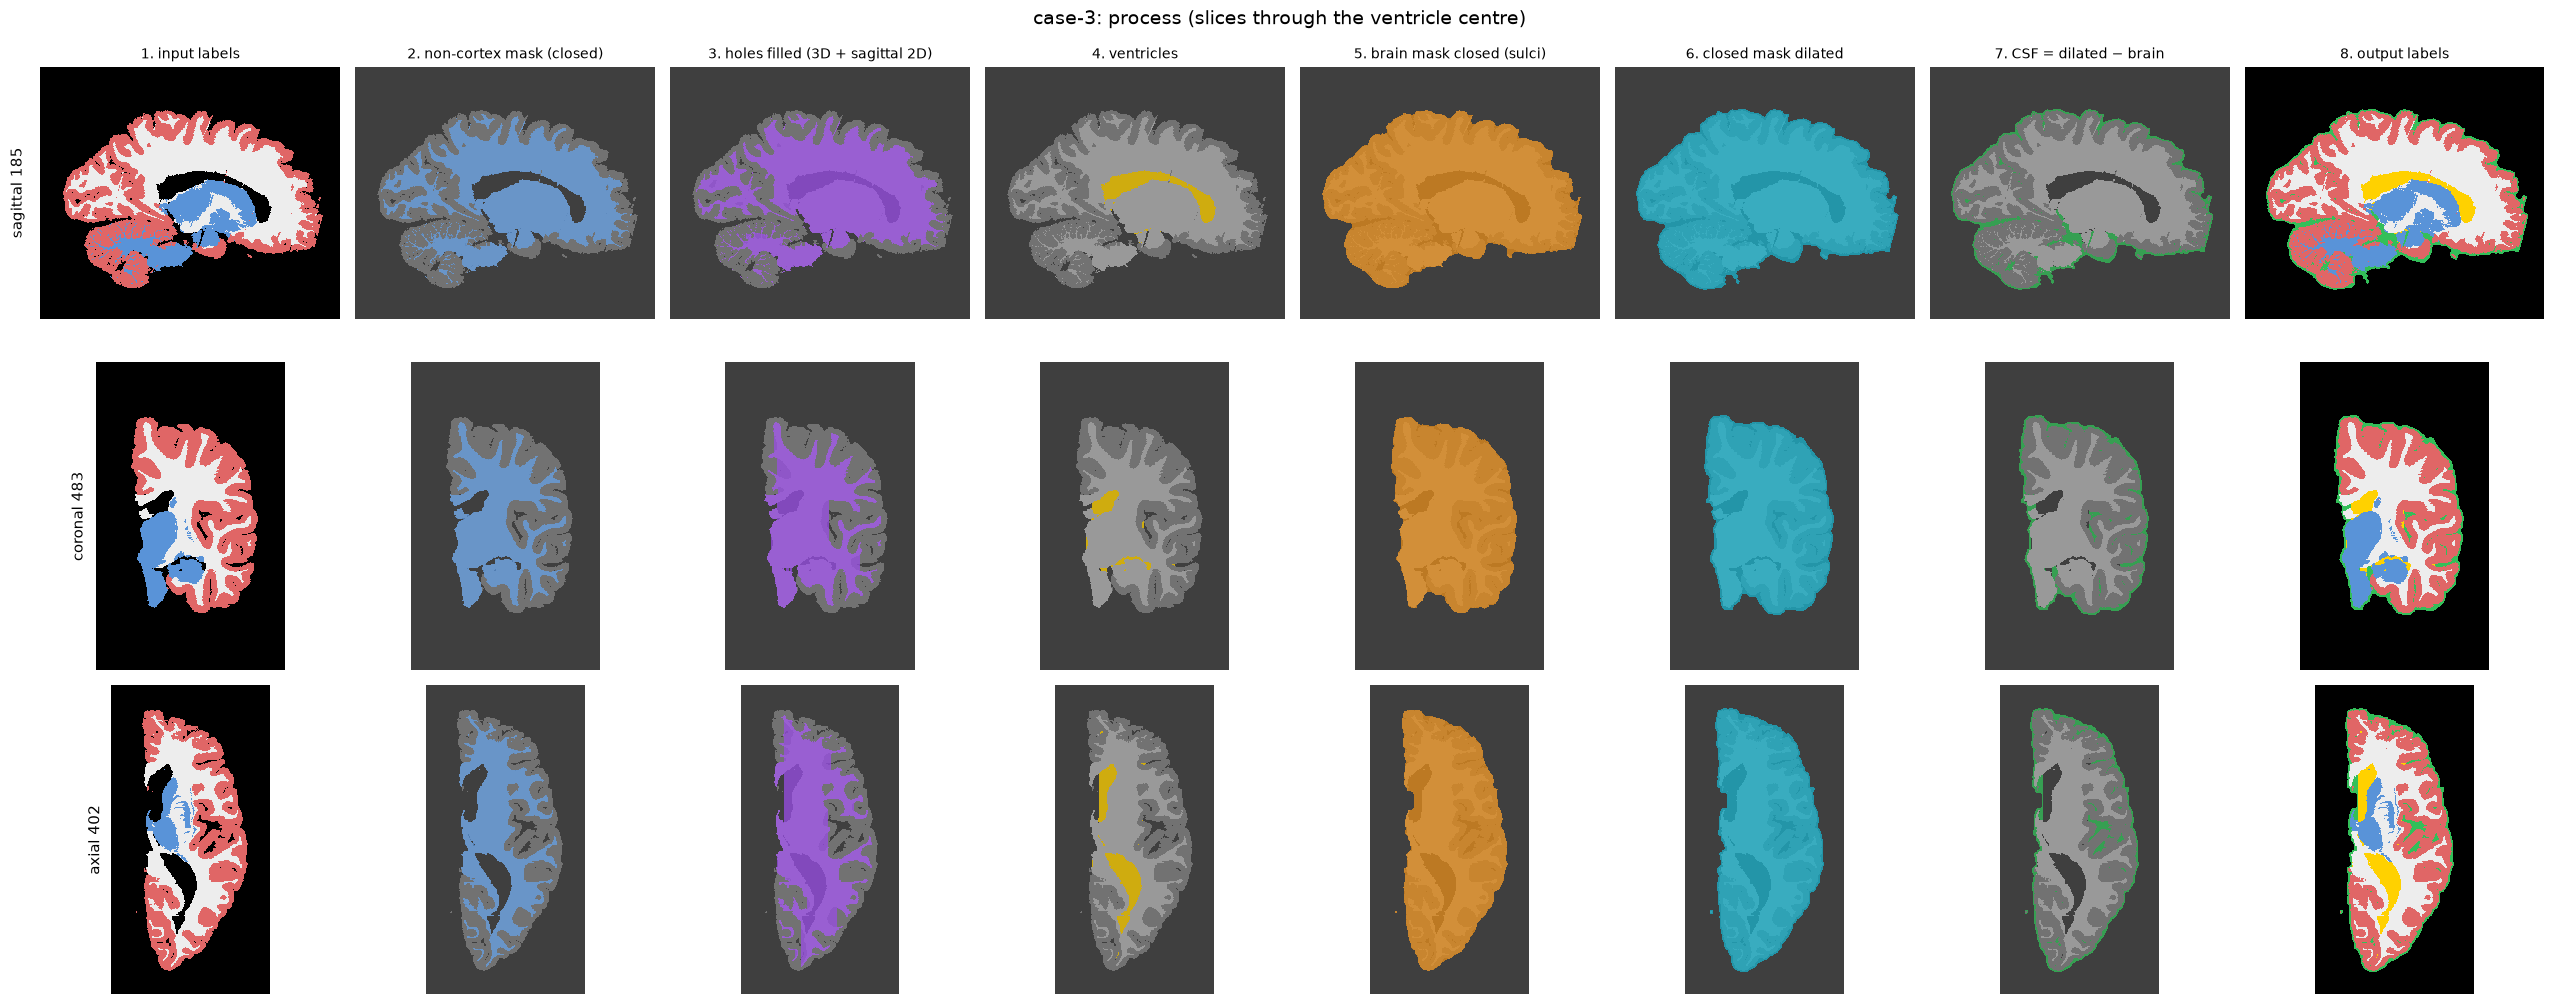

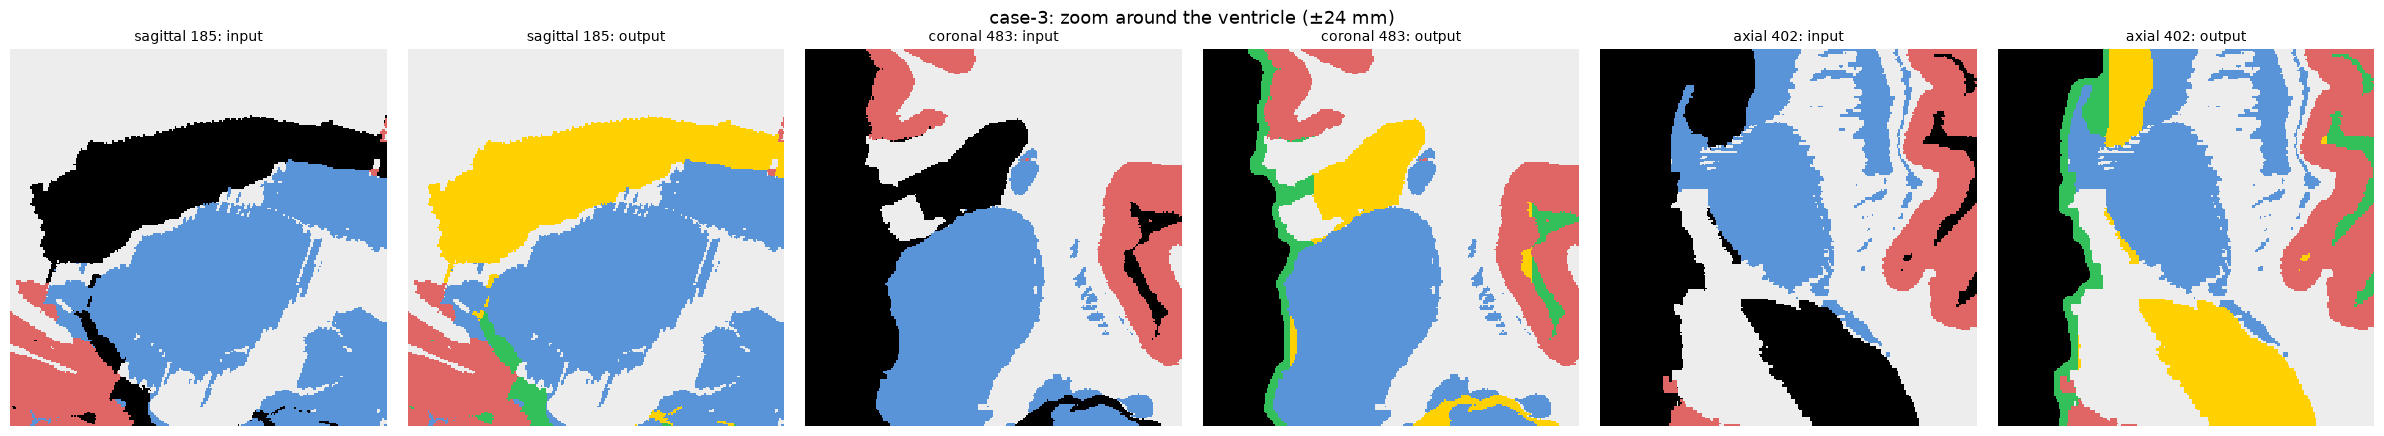

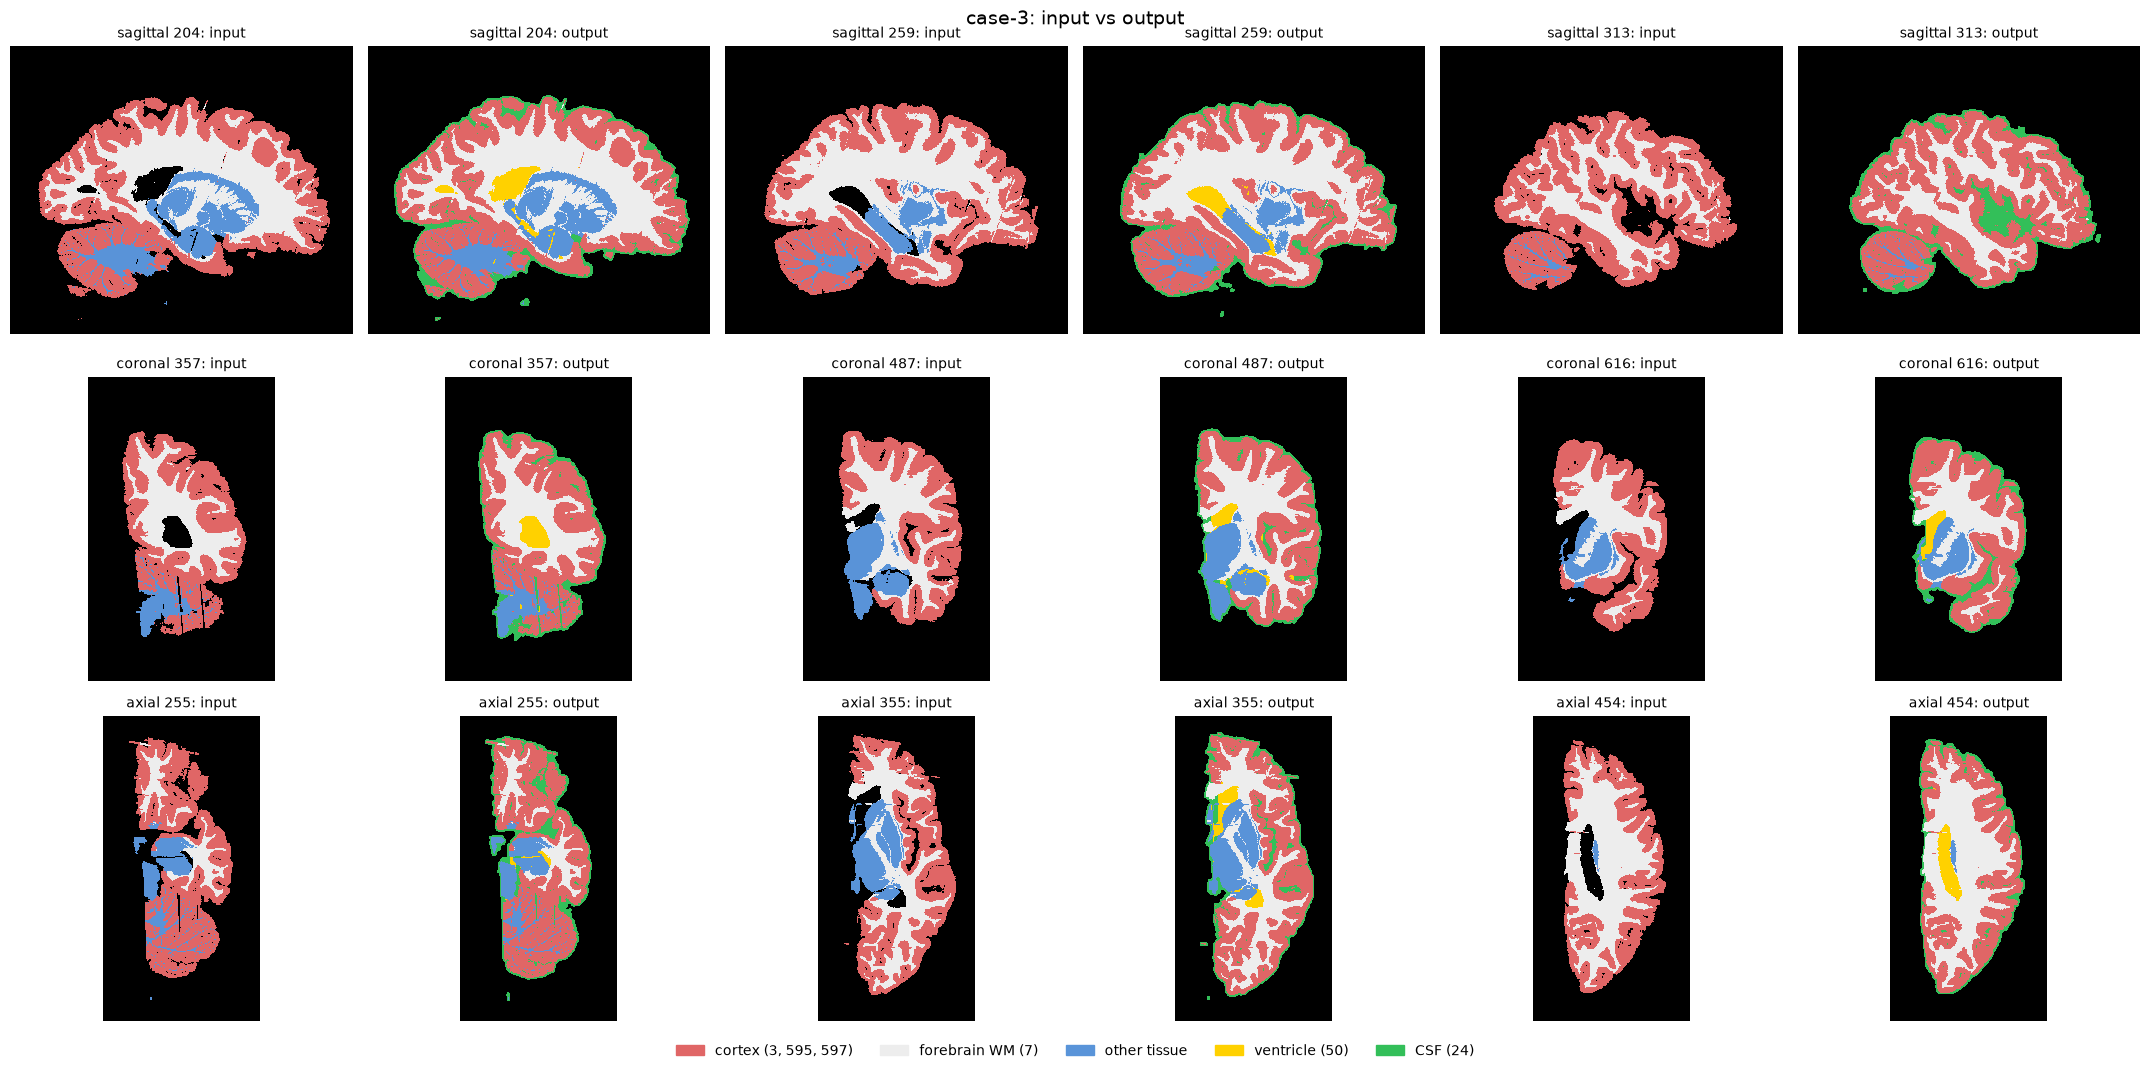

In [6]:
case = "case-3"
d = load_case(case)
vox = float(np.prod(nib.load(IN_DIR / f"{case}.nii.gz").header.get_zooms()[:3]))
rows = globals().setdefault("ROWS", {})
rows[case] = volumes(case, d, vox)
print(rows[case])
plot_process(case, d)
plot_zoom(case, d)
plot_result(case, d)
del d

### case-4

{'case': 'case-4', 'tissue (cm3)': 652.1323029746204, 'ventricle (cm3)': 10.887448517126032, 'CSF (cm3)': 94.08927646900061, 'small pockets filled (cm3)': np.float64(0.16713600793853403)}


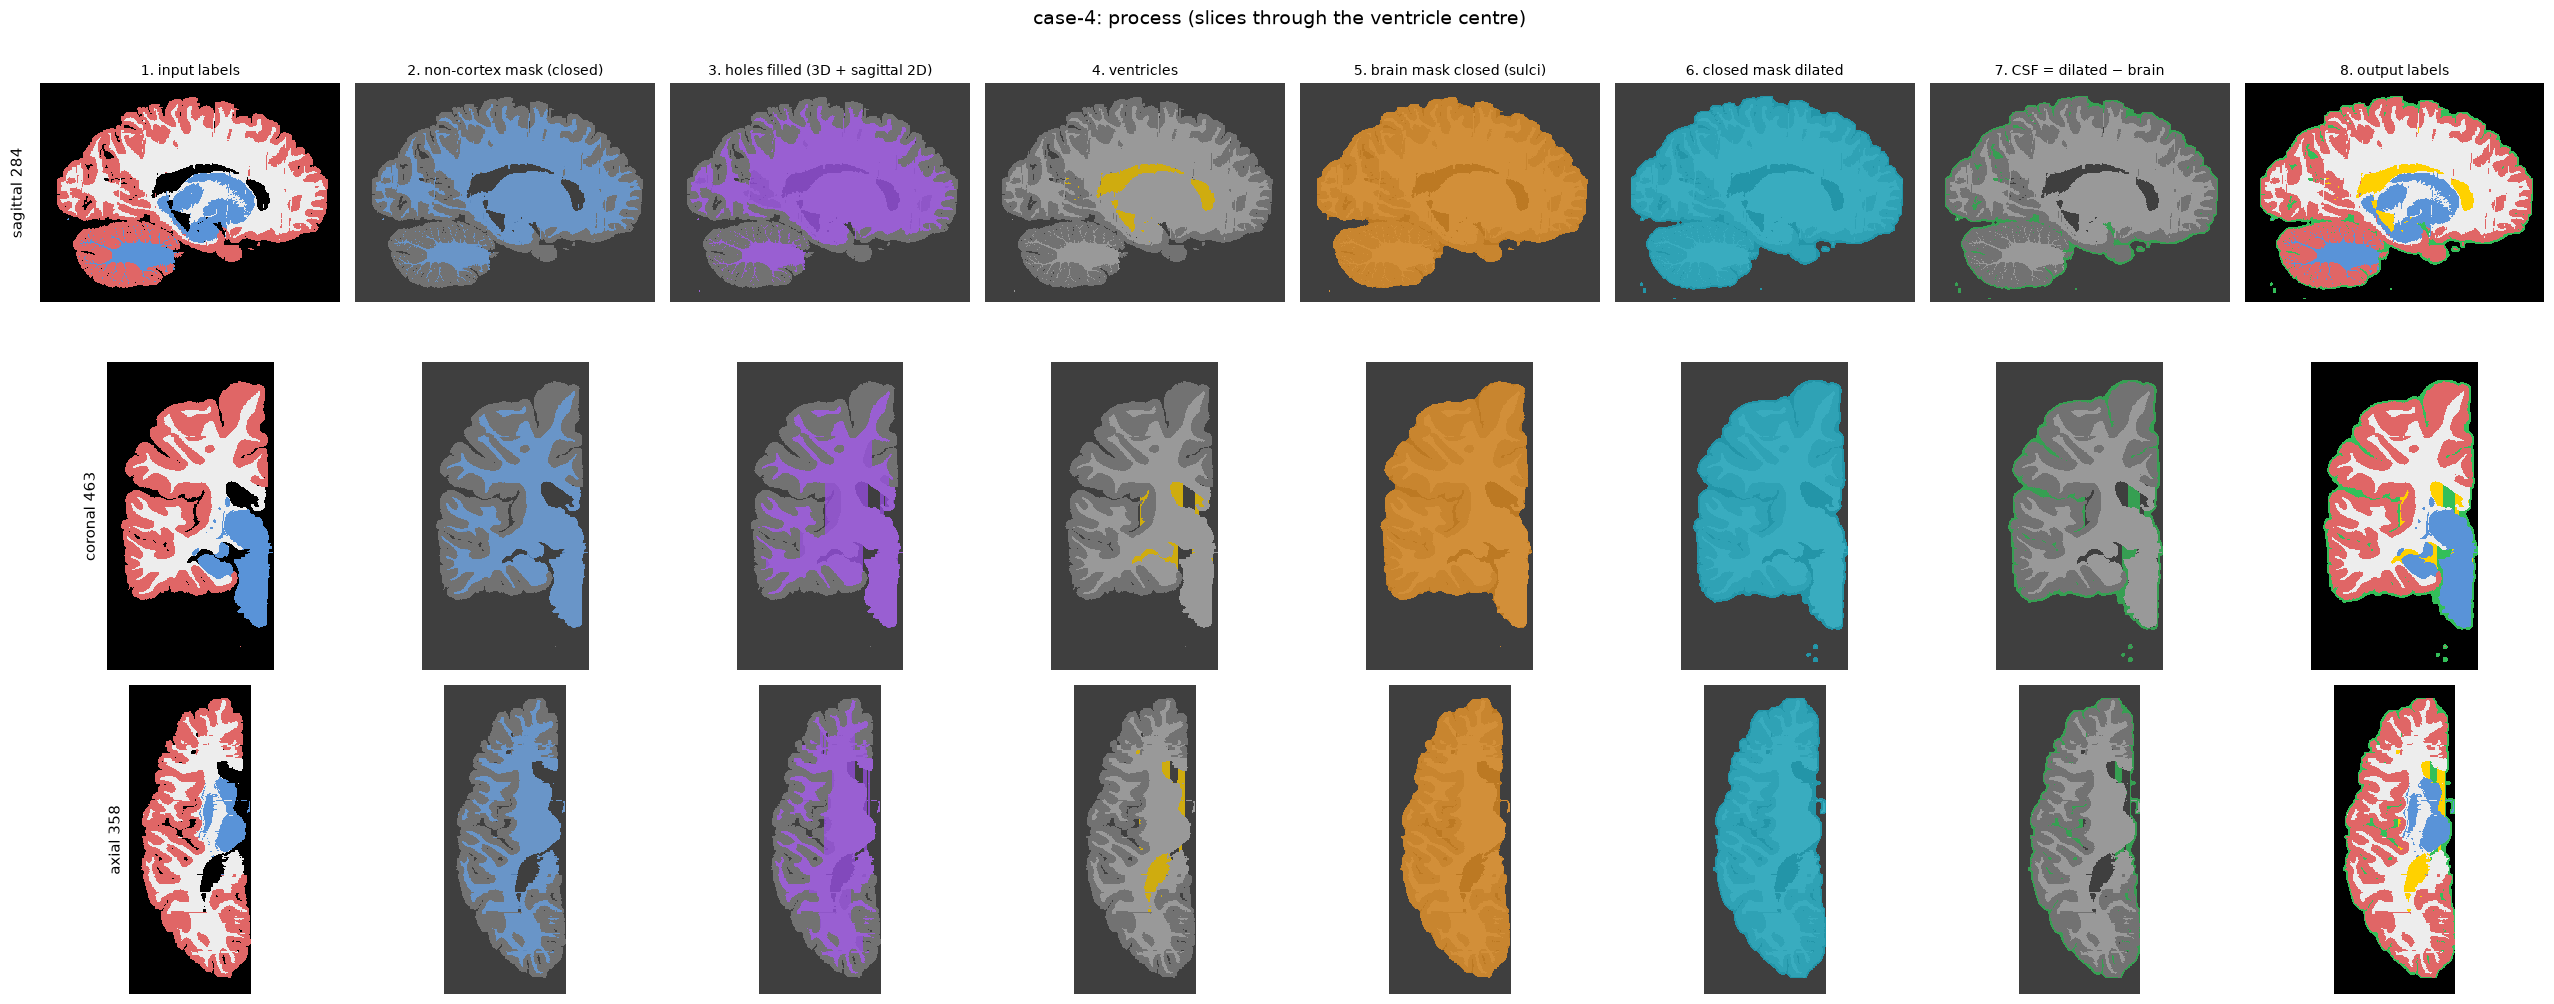

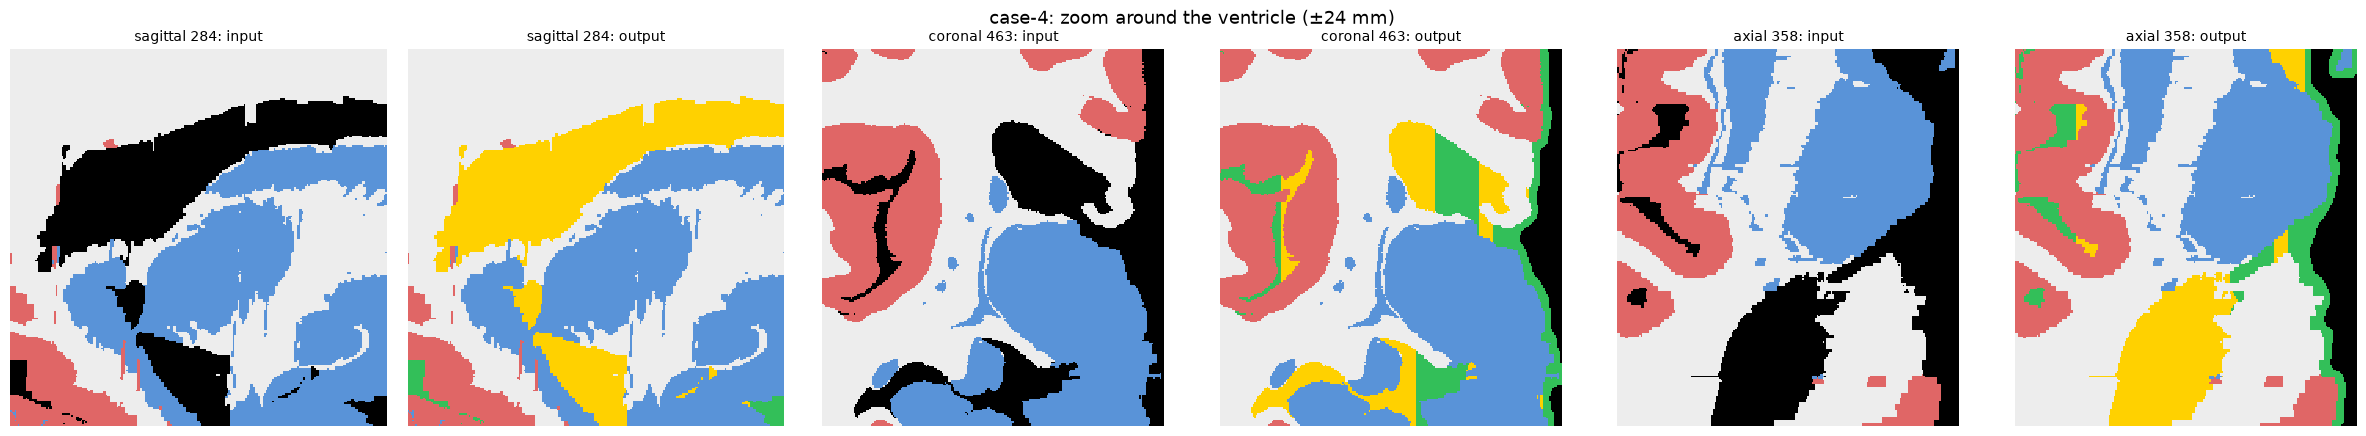

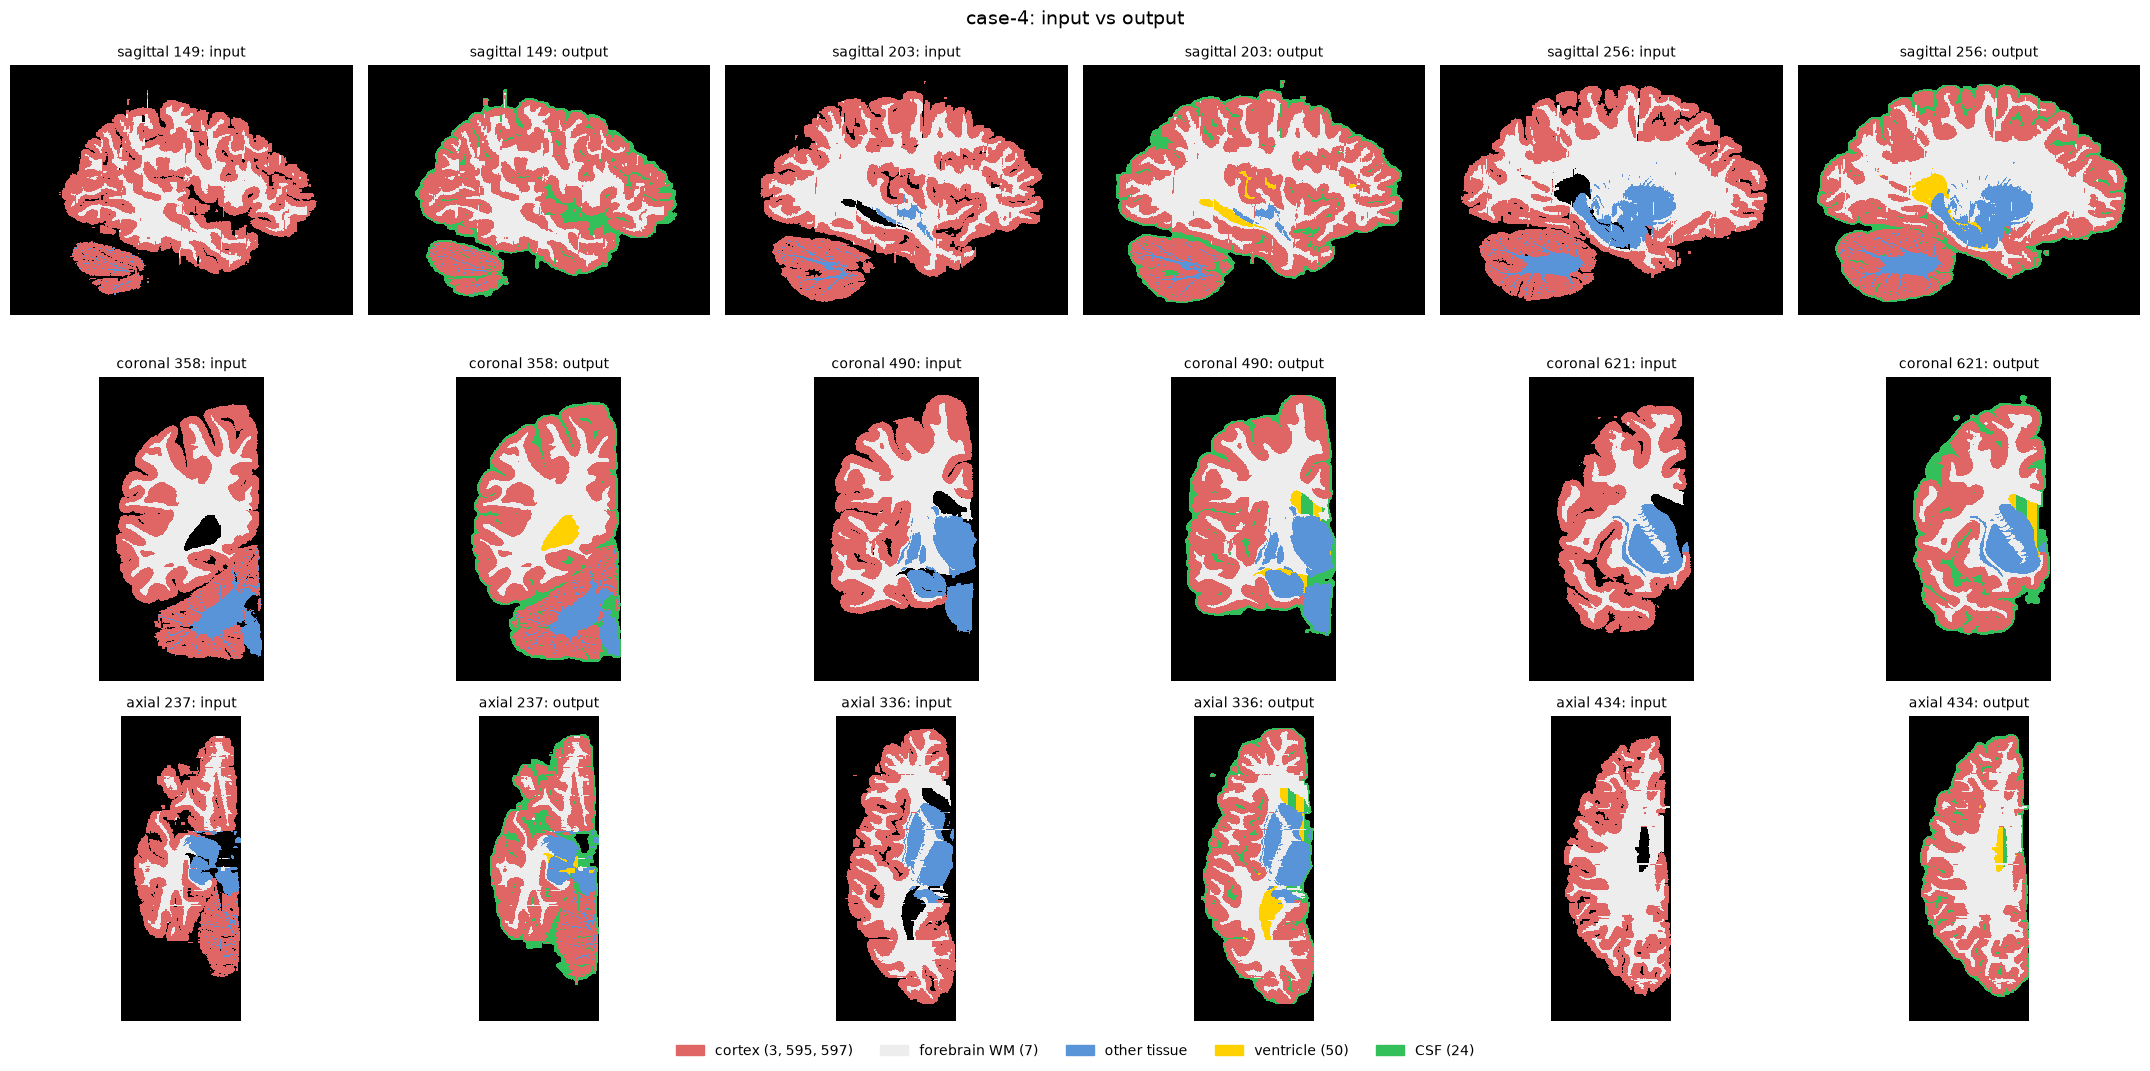

In [7]:
case = "case-4"
d = load_case(case)
vox = float(np.prod(nib.load(IN_DIR / f"{case}.nii.gz").header.get_zooms()[:3]))
rows = globals().setdefault("ROWS", {})
rows[case] = volumes(case, d, vox)
print(rows[case])
plot_process(case, d)
plot_zoom(case, d)
plot_result(case, d)
del d

### case-5

{'case': 'case-5', 'tissue (cm3)': 597.4534683775153, 'ventricle (cm3)': 11.497616546107457, 'CSF (cm3)': 84.20788399965969, 'small pockets filled (cm3)': np.float64(0.18026400856208055)}


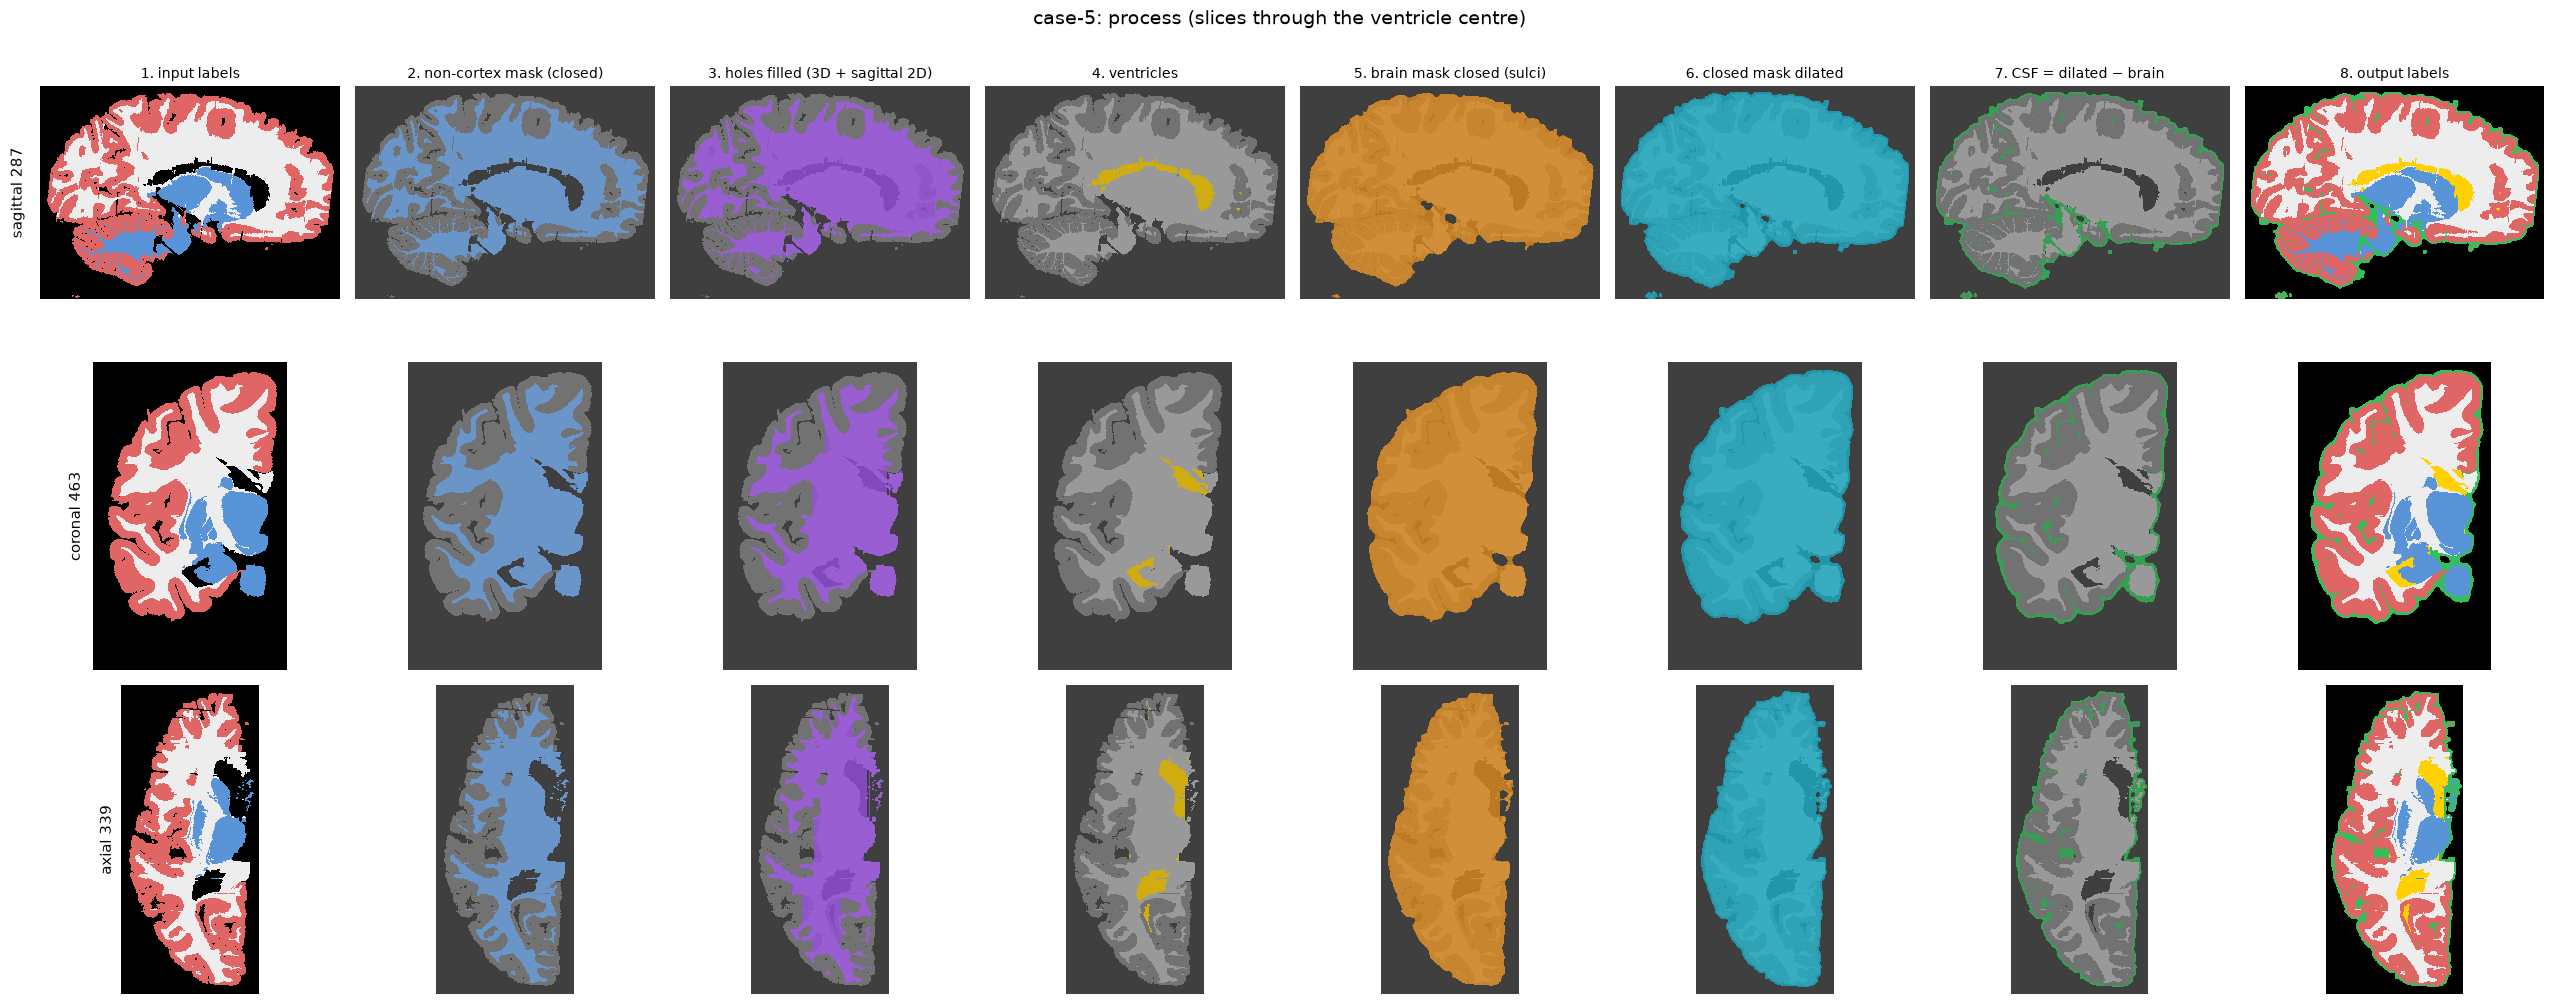

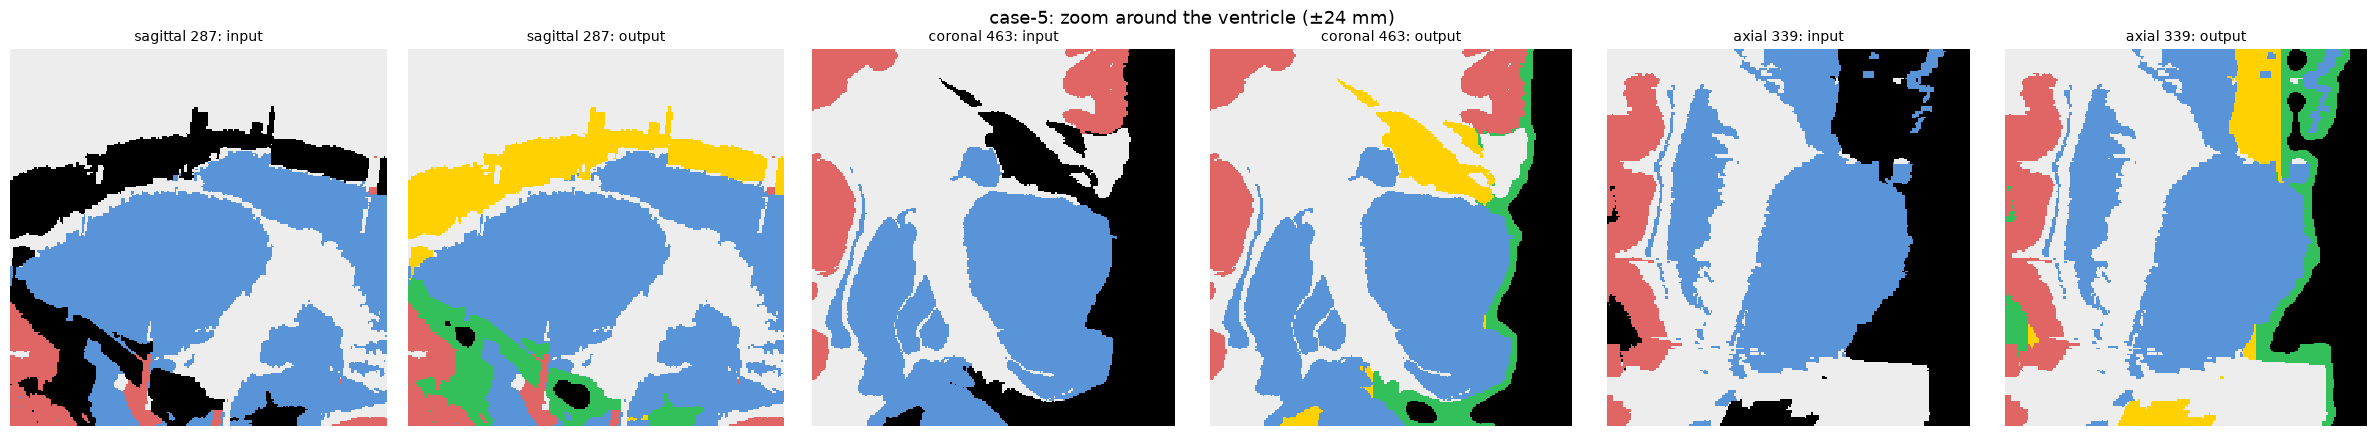

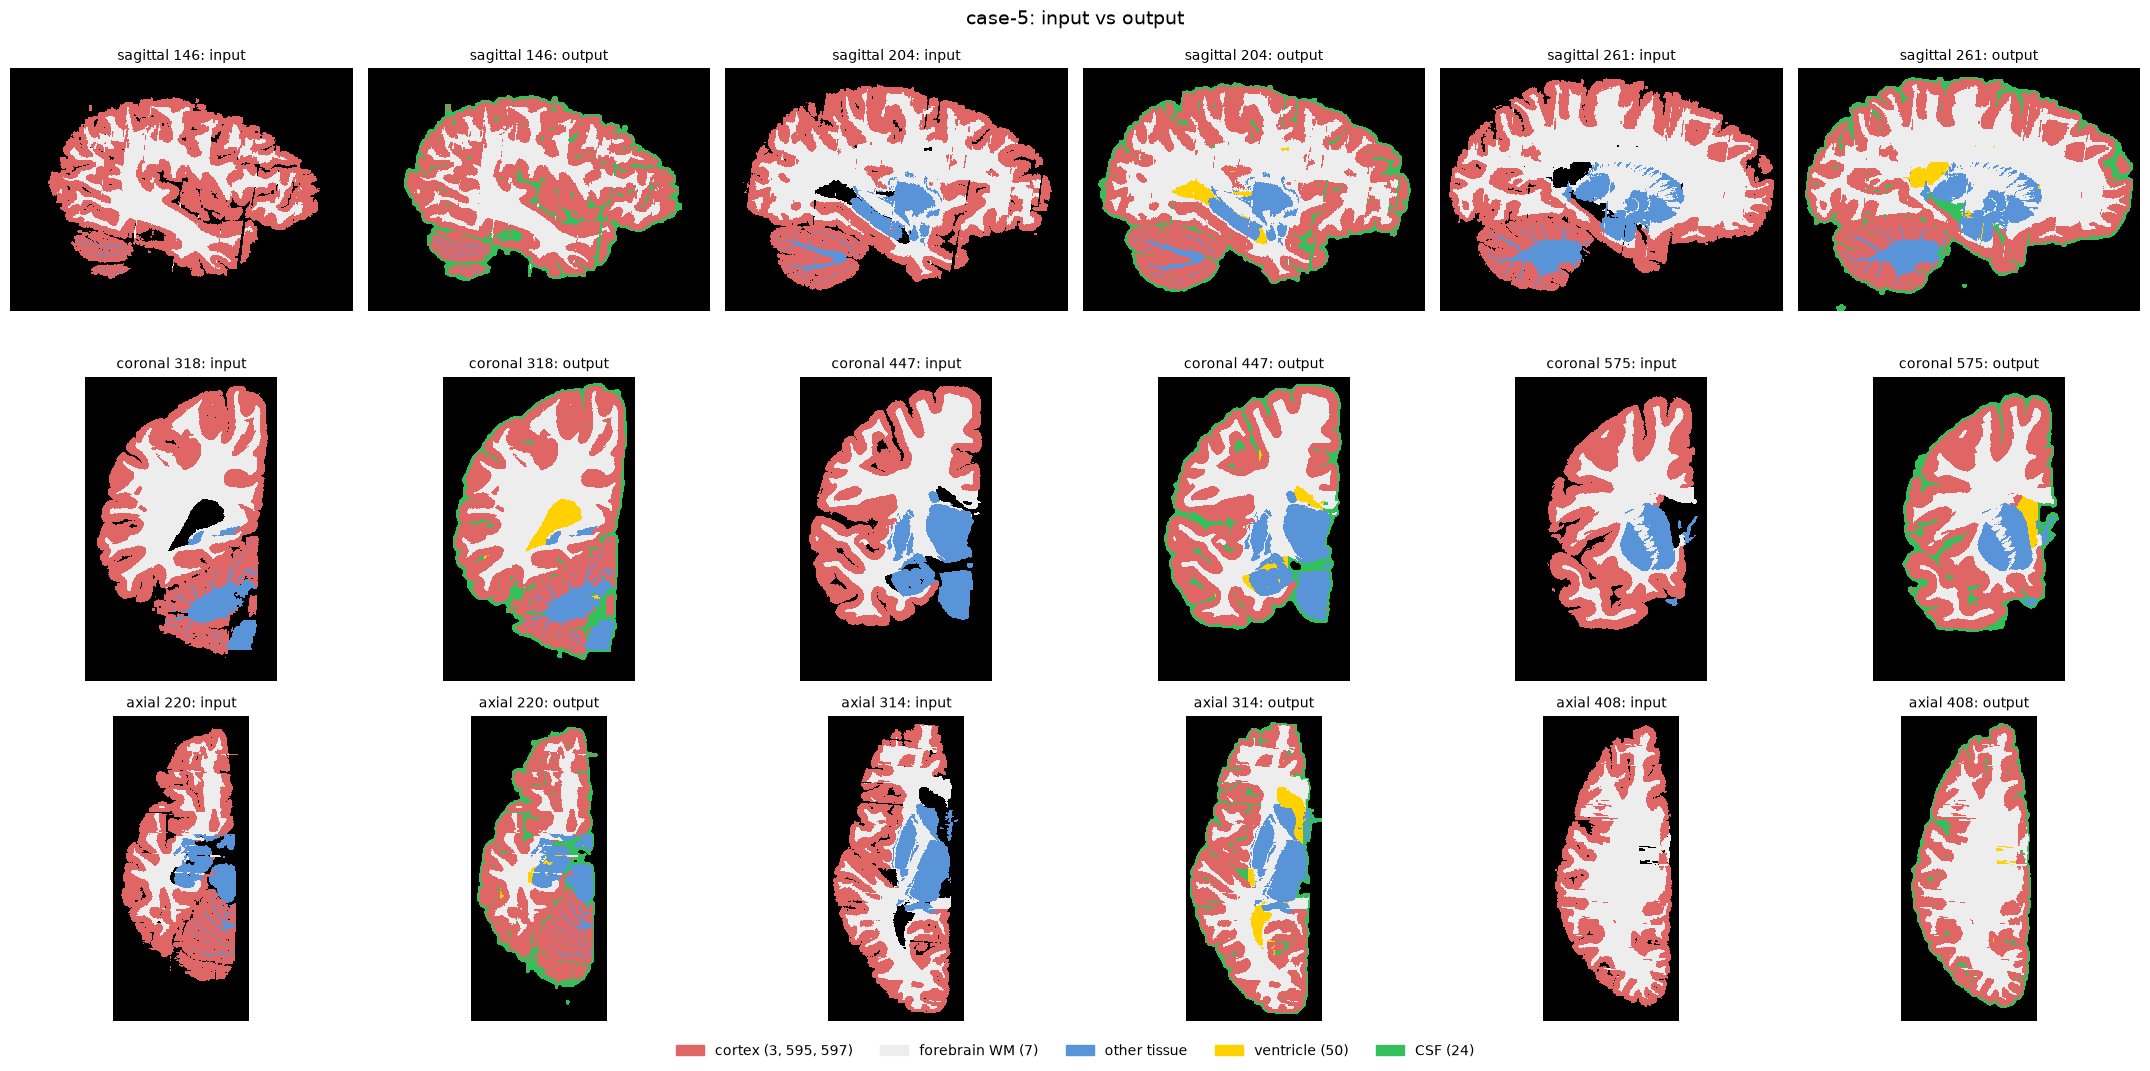

In [8]:
case = "case-5"
d = load_case(case)
vox = float(np.prod(nib.load(IN_DIR / f"{case}.nii.gz").header.get_zooms()[:3]))
rows = globals().setdefault("ROWS", {})
rows[case] = volumes(case, d, vox)
print(rows[case])
plot_process(case, d)
plot_zoom(case, d)
plot_result(case, d)
del d

## Volume summary

,tissue (cm3),ventricle (cm3),CSF (cm3),small pockets filled (cm3),ventricle / tissue (%),CSF / tissue (%)
case,,,,,,
case-1,544.23,9.19,75.19,0.15,1.69,13.82
case-2,509.55,14.54,64.00,0.15,2.85,12.56
case-3,567.03,14.67,80.04,0.18,2.59,14.12
case-4,652.13,10.89,94.09,0.17,1.67,14.43
case-5,597.45,11.50,84.21,0.18,1.92,14.09


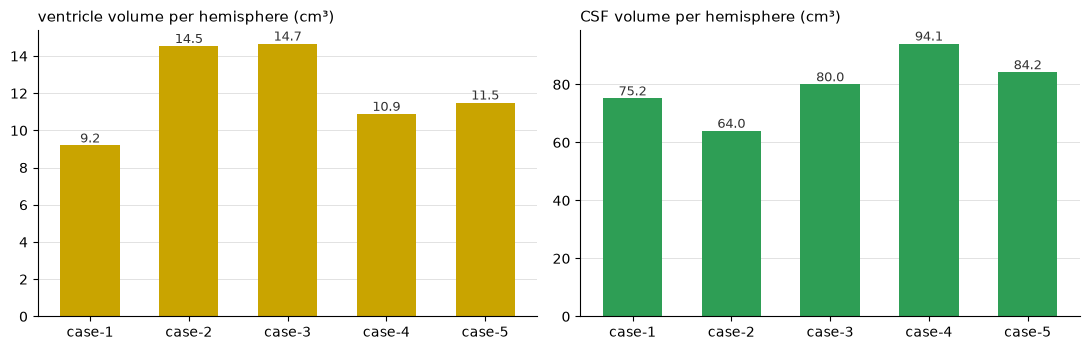

In [9]:
df = pd.DataFrame([ROWS[c] for c in CASES]).set_index("case").round(2)
df["ventricle / tissue (%)"] = (100 * df["ventricle (cm3)"] / df["tissue (cm3)"]).round(2)
df["CSF / tissue (%)"] = (100 * df["CSF (cm3)"] / df["tissue (cm3)"]).round(2)
display(df)

# two separate charts (different scales): ventricle and CSF volume per case
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, color in [(axes[0], "ventricle (cm3)", "#c9a400"), (axes[1], "CSF (cm3)", "#2e9e55")]:
    bars = ax.bar(df.index, df[col], color=color, width=0.6)
    ax.bar_label(bars, fmt="%.1f", fontsize=9, color="#333")
    ax.set_title(col.replace(" (cm3)", " volume per hemisphere (cm³)"), fontsize=11, loc="left")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="y", color="#ddd", linewidth=0.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()